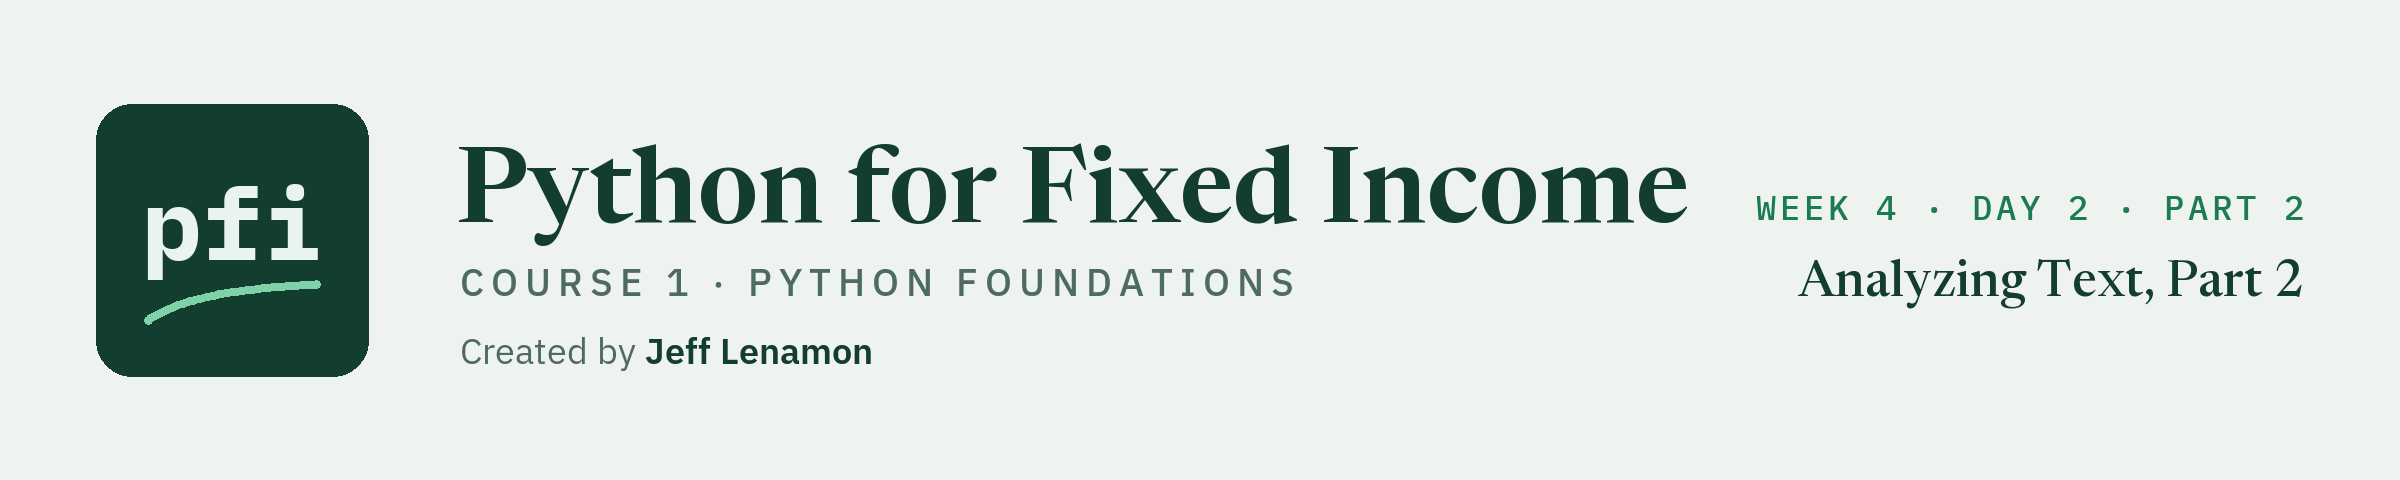

# Analyzing Text, Part 2

Week 4, Day 2, Part 2. Clean a statement in steps, count its words, and do the same to a table of 46 statements.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2_part2/17_part2_analyzing_text.ipynb)

## The Desk Lead's Note

> Part 1 proved the tools on one statement. Now my table: one row for each of the 46. How long each is, the rate range it states, how often a few plain words appear, and how much of its wording it shares with the statement before. Clean the text first so `Inflation` and `inflation.` count as one word, and show me what each step does to the count. Counts only: no reading of policy.

<table align="left">
<tr><th align="left">The statements</th><th align="left"></th></tr>
<tr><td align="left">Source</td><td align="left">Board of Governors of the Federal Reserve System, each statement from its press release: https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm</td></tr>
<tr><td align="left">Retrieved</td><td align="left">2026-10-03</td></tr>
<tr><td align="left">Span</td><td align="left">46, 2021-01-27 to 2026-09-16, every scheduled meeting</td></tr>
<tr><td align="left">Reuse</td><td align="left">Public domain, citing the Board as the source: https://www.federalreserve.gov/disclaimer.htm</td></tr>
<tr><td align="left">Changes</td><td align="left">White space only</td></tr>
</table>
<br clear="left">

A quote prints the file's own words, with the statement's date.

**Four columns: length, the range, word counts, wording shared.**

## 17.7 Every Statement's Length

### As in Part 1

Q. Load the statements, Part 1's statement of 2023-11-01, its range sentence, and its range pattern.

In [1]:
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Part 1
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the repo's data folder on your machine; in Colab, GitHub
if os.path.exists('../../../data/fomc_statements.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
statements = pd.read_csv(data_folder + 'fomc_statements.csv')
statement = statements.loc[statements['date'] == '2023-11-01', 'text'].iloc[0]
# the second sentence of the third paragraph, its full stop put back
sentence = statement.split('\n')[2].split('. ')[1] + '.'
range_pattern = r'[\d/-]+ to [\d/-]+ percent'
print(statements.shape, len(statement))

(46, 3) 2300


### A String Method on a Column

Q. Put every statement in lower case with week 1's Day 1 `lower()`.

In [2]:
# the string method, called on the whole column
statements['text'].lower()

AttributeError: 'Series' object has no attribute 'lower'

Read the last line, as on week 1's Day 3: a column is a Series, and a Series has no `lower()`.
The EDA notebook's `.str` runs a string method on every value.

In [3]:
# .str.lower() lowers each of the 46 texts
lower_text = statements['text'].str.lower()
print(lower_text.iloc[0][:60])

the federal reserve is committed to using its full range of 


### Characters and Words

Q. How long is each statement, in characters and in words?

In [4]:
# .str.len() counts each text's characters
statements['characters'] = statements['text'].str.len()
# .str.split() makes each text a list of words; .str.len() then counts each list's items
statements['words'] = statements['text'].str.split().str.len()
# real dates and the year of each, as in Combining Part 2
statements['meeting'] = pd.to_datetime(statements['date'], format='%Y-%m-%d')
statements['year'] = statements['meeting'].dt.year
print(round(statements['words'].mean(), 1), statements['words'].median())

359.3 344.5


359.3 against 344.5: a few long statements pull the mean above the median.

**Excel side by side.** With one statement per row, `=LOWER(C2)` and `=LEN(C2)` filled down do what `.str.lower()` and `.str.len()` do.

### Words Over Time

Q. Which statement is longest, which shortest, and what is each year's mean?

In [5]:
# the Visualization notebook's idxmax(), and its twin idxmin(): the longest and shortest rows
longest = statements.loc[statements['words'].idxmax()]
shortest = statements.loc[statements['words'].idxmin()]
print(longest['date'], longest['words'], shortest['date'], shortest['words'])
# the words of the last three statements
print(statements['words'].tail(3).tolist())
statements.groupby('year')['words'].agg(['count', 'mean', 'min', 'max']).round(1)

2021-11-03 614 2026-06-17 131
[131, 167, 131]


,count,mean,min,max
year,,,,
2021,8,505.5,474,614
2022,8,361.1,313,430
2023,8,342.5,331,365
2024,8,348.5,318,406
2025,8,337.5,295,386
2026,6,228.0,131,341


Q. Draw every statement's length over time, the longest and the shortest named.

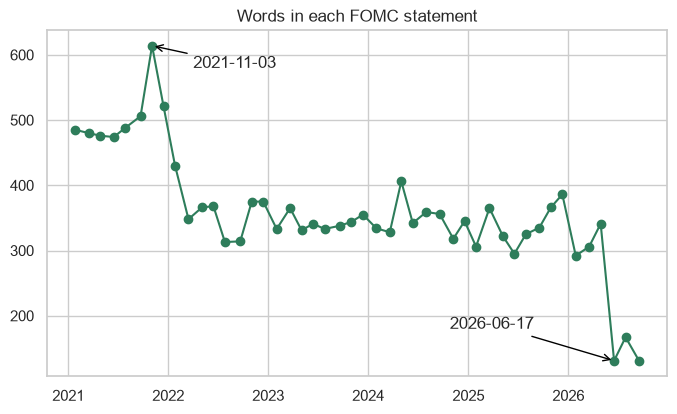

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(statements['meeting'], statements['words'], marker='o')
# pd.Timedelta(days=) is a length of time; color= turns the theme's white arrows black
arrow = {'arrowstyle': '->', 'color': 'black'}
ax.annotate(longest['date'], xy=(longest['meeting'], longest['words']),
            xytext=(longest['meeting'] + pd.Timedelta(days=150), 580), arrowprops=arrow)
ax.annotate(shortest['date'], xy=(shortest['meeting'], shortest['words']),
            xytext=(shortest['meeting'] - pd.Timedelta(days=600), 180), arrowprops=arrow)
ax.set_title('Words in each FOMC statement')
plt.show()

2021 ran longest; the last three, from 2026-06-17 on, run 131, 167 and 131 words.
A length says how long, never why.

**Length needed no cleaning. Counting a word does.**

## 17.8 Cleaning Text in Steps

`Inflation` and `inflation` are one word to a reader and two strings to Python; so are `percent.` and `percent`.

### Step 0: Split as It Is

Q. Split the sentence with no cleaning. How many pieces?

In [7]:
print(sentence)
# Part 1's split(): it cuts at spaces and nothing else
pieces = sentence.split()
print(len(pieces), pieces)

In support of these goals, the Committee decided to maintain the target range for the federal funds rate at 5-1/4 to 5-1/2 percent.
23 ['In', 'support', 'of', 'these', 'goals,', 'the', 'Committee', 'decided', 'to', 'maintain', 'the', 'target', 'range', 'for', 'the', 'federal', 'funds', 'rate', 'at', '5-1/4', 'to', '5-1/2', 'percent.']


23 pieces: `'In'` keeps its capital, `'goals,'` its comma, `'percent.'` its full stop.

### Steps 1 and 2: Lower Case, Letters Only

Q. Lower the case, then turn every character that is not a letter or white space into a space.

In [8]:
# step 1: week 1's Day 1 lower()
step1 = sentence.lower()
# step 2: Part 1's [^...]: anything but a to z or white space becomes a space
step2 = re.sub(r'[^a-z\s]', ' ', step1)
print(step2)

in support of these goals  the committee decided to maintain the target range for the federal funds rate at       to       percent 


Dropping the digits is a decision: Part 1 already took the figures from the text as published.
A space, not `''`, or `longer-run` would close up as `longerrun`.
Lower case came first, so `[a-z]` covers every letter.

### Steps 3 and 4: One Space, Then Tokens

Q. Make every run of white space one space, then split.

In [9]:
# step 3: \s+ is a run of white space; strip() drops the space left at the end
step3 = re.sub(r'\s+', ' ', step2).strip()
# step 4: split at the single spaces
tokens = step3.split(' ')
print(len(tokens), tokens)

21 ['in', 'support', 'of', 'these', 'goals', 'the', 'committee', 'decided', 'to', 'maintain', 'the', 'target', 'range', 'for', 'the', 'federal', 'funds', 'rate', 'at', 'to', 'percent']


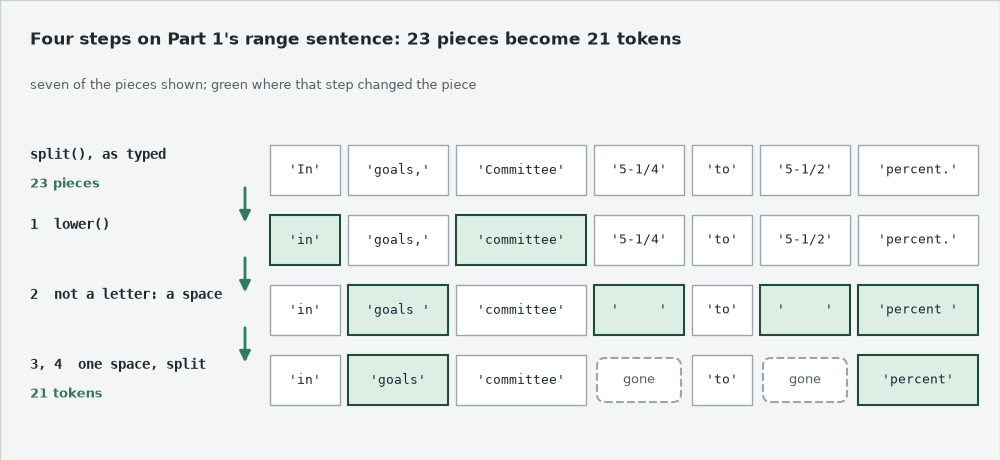

21 **tokens**: a token is one unit of text after cleaning, here a word.
On a whole statement `\s` also takes the line breaks, so step 3 joins the paragraphs.

### Four Steps in One Function

Q. Put the four steps in a function, as in week 1's Day 1 Part 2. Does it give the same 21?

In [10]:
def clean(text):
    # steps 1 and 2: lower case, then letters and white space only
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    # steps 3 and 4: one space between words, then the tokens
    text = re.sub(r'\s+', ' ', text).strip()
    return text.split(' ')


print(clean(sentence) == tokens)

True


### Predict 1: An Apostrophe

**Predict 1**

Q. The statement holds the phrase `the Committee's goals.` How many tokens does `clean()` return for it?

A) 3: `the`, `committees`, `goals`.
B) 3: `the`, `committee`, `goals`.
C) 4.

In [11]:
# double quotes, since the pattern holds an apostrophe: the, a word, 's, a word, a full stop
phrase = re.search(r"the \w+'s \w+\.", statement).group(0)
print(phrase, clean(phrase))

the Committee's goals. ['the', 'committee', 's', 'goals']


C: the apostrophe became a space, and the `s` stands as a token of its own.

### The Whole Statement

Q. Clean the whole statement. How many tokens?

In [12]:
statement_tokens = clean(statement)
# Part 1's split() count, then the token count
print(len(statement.split()), len(statement_tokens))

344 343


343 tokens from 344 pieces: the figures went, while `Committee's`, `U.S.` and `mortgage-backed` each split in two.

**Excel side by side.** A sentence in A2, each step in the next column, B to E:

<table align="left">
<tr><th align="left">Step</th><th align="left">Excel</th></tr>
<tr><td align="left">Lower case</td><td align="left"><code>=LOWER(A2)</code></td></tr>
<tr><td align="left">Letters and white space only</td><td align="left"><code>=REGEXREPLACE(B2, "[^a-z\s]", " ")</code>, Microsoft 365 only</td></tr>
<tr><td align="left">One space between words</td><td align="left"><code>=TRIM(C2)</code></td></tr>
<tr><td align="left">Tokens</td><td align="left"><code>=TEXTSPLIT(D2, " ")</code>, Microsoft 365 and Excel 2024</td></tr>
</table>
<br clear="left">

`TRIM` squeezes ordinary spaces, not a line break or `CHAR(160)`; without `REGEXREPLACE`, step 2 is a nested `SUBSTITUTE` per character.
On the whole statement, Part 1's `=COUNTA(TEXTSPLIT(A2, " "))` gives 340 words, not 344: the four line breaks between paragraphs are not spaces until `SUBSTITUTE(A2, CHAR(10), " ")` makes them so.

**343 tokens, and more than a third of them say nothing.**

## 17.9 Stopwords

### The Most Common Tokens

Q. Which tokens does the statement use most?

In [13]:
# Counter comes with Python: it counts how often each value in a list appears
from collections import Counter

counts = Counter(statement_tokens)
# most_common(10): the ten highest, as (token, count) pairs
print(len(counts), counts.most_common(10))

180 [('the', 29), ('and', 16), ('to', 12), ('of', 11), ('committee', 11), ('inflation', 9), ('in', 7), ('policy', 7), ('monetary', 6), ('economic', 5)]


180 different tokens, and the top four, led by `the` at 29, are grammar.
A `Counter` is a dictionary that counts: `counts['inflation']` is 9, and a token not there gives 0.
Words that hold any sentence together and say nothing of its subject are **stopwords**.

### A List Typed by Hand

Q. Remove ten common words, typed by hand. What is left on top?

In [14]:
short_list = ['the', 'of', 'to', 'and', 'a', 'in', 'is', 'that', 'for', 'its']
# week 1's Day 1 Part 2 comprehension with a filter: keep a token only if it is not on the list
short_kept = [token for token in statement_tokens if token not in short_list]
print(len(short_kept), Counter(short_kept).most_common(8))

252 [('committee', 11), ('inflation', 9), ('policy', 7), ('monetary', 6), ('economic', 5), ('will', 5), ('s', 4), ('percent', 4)]


252 left, but `will` and the stray `s` still sit near the top: a short list misses words.

### The Stopword List in `nltk`

`nltk`, the Natural Language Toolkit, is in the course's `requirements.txt` and ships a longer list.

Q. Load nltk's English stopwords. Is the lone `s` one of them?

In [15]:
import nltk

# a small file, downloaded once and kept; quiet=True hides the progress lines
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

stop_words = stopwords.words('english')
print(len(stop_words), 's' in stop_words)

198 True


198 lower-case words, `s` among them.
The first run needs the internet; nltk revises the list now and then, which moves the counts below.

Q. Remove nltk's stopwords. How many tokens are left, and how many different ones?

In [16]:
kept = [token for token in statement_tokens if token not in stop_words]
# set() keeps each different value once, so len(set(...)) counts the different tokens
print(len(kept), len(set(statement_tokens)), len(set(kept)))
print(Counter(kept).most_common(5))

217 180 152
[('committee', 11), ('inflation', 9), ('policy', 7), ('monetary', 6), ('economic', 5)]


`committee` now leads with 11: a count, not a conclusion.

### Before and After

Q. Draw the top ten before and after nltk's list, side by side.

In [17]:
# dict() makes the (token, count) pairs a dictionary, and pd.Series() labelled counts
# [::-1] reverses a Series, so the most common is drawn at the top
before = pd.Series(dict(counts.most_common(10)))[::-1]
after = pd.Series(dict(Counter(kept).most_common(10)))[::-1]

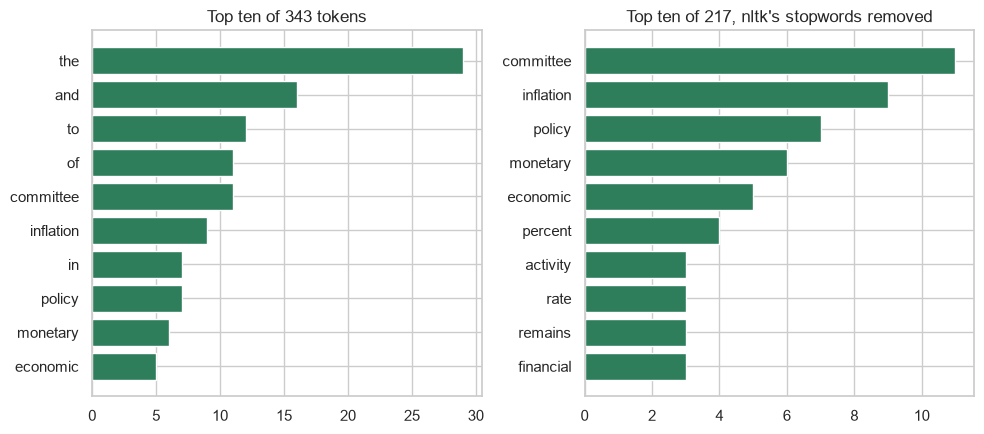

In [18]:
# More Visualization's two panels side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].barh(before.index, before)
axes[0].set_title('Top ten of 343 tokens')
axes[1].barh(after.index, after)
axes[1].set_title("Top ten of 217, nltk's stopwords removed")
plt.tight_layout()
plt.show()

**Excel side by side.** The 343 tokens in B2:B344, nltk's list in column A of a sheet named `stop`:

<table align="left">
<tr><th align="left">Job</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Count one token</td><td align="left"><code>=COUNTIF(B2:B344, "the")</code></td><td align="left">29</td></tr>
<tr><td align="left">Is it a stopword</td><td align="left"><code>=COUNTIF(stop!A:A, B2)&gt;0</code>, filled down</td><td align="left">TRUE or FALSE</td></tr>
<tr><td align="left">Keep the rest</td><td align="left"><code>=FILTER(B2:B344, COUNTIF(stop!A:A, B2:B344)=0)</code></td><td align="left">217 tokens</td></tr>
</table>
<br clear="left">

`FILTER` is in Excel 2021 and Microsoft 365; `COUNTIF` in every version.

**217 left, and `committee` leads. Forms of one word still count apart.**

## 17.10 Stemming

**Stemming** cuts off a word's ending, so `remain`, `remained` and `remains` count as one; what is left is the **stem**.
nltk's Porter stemmer applies fixed rules about English endings.

### One Root for Several Forms

Q. Stem two words' forms, then five words from the statement.

In [19]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()
# stem() takes one word and returns its stem
for word in ['remain', 'remained', 'remains', 'assess', 'assessing', 'assessments',
             'inflation', 'policy', 'committee', 'monetary', 'securities']:
    print(word, '->', stemmer.stem(word))

remain -> remain
remained -> remain
remains -> remain
assess -> assess
assessing -> assess
assessments -> assess
inflation -> inflat
policy -> polici
committee -> committe
monetary -> monetari
securities -> secur


The forms meet, but `polici` and `monetari` show that **a stem is not a word**: the rules look nothing up.

### Predict 2: `economic` and `economy`

**Predict 2**

Q. Does the Porter stemmer give `economic` and `economy` the same stem?

A) Yes: both become `econom`.
B) No: two different stems.
C) Neither changes: both stay as typed.

In [20]:
# two forms a reader would put together, then two pairs that differ in meaning
for word in ['economic', 'economy', 'production', 'productivity', 'time', 'timing']:
    print(word, '->', stemmer.stem(word))

economic -> econom
economy -> economi
production -> product
productivity -> product
time -> time
timing -> time


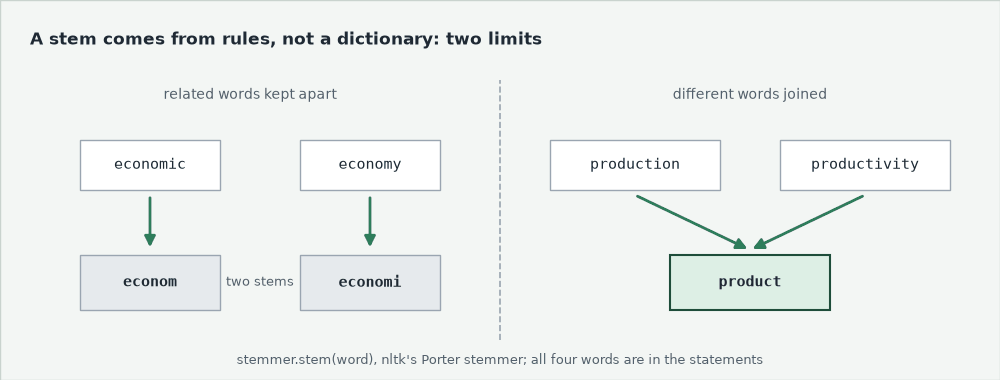

B: `econom` and `economi`, kept apart, while `production` and `productivity` join as `product`.
All six words are in the statements.

### Stems in the Statement

Q. Stem the 217 kept tokens. What changes in the counts?

In [21]:
stems = [stemmer.stem(token) for token in kept]
print(len(stems), len(set(kept)), len(set(stems)))
print(Counter(stems).most_common(6))

217 152 146
[('committe', 11), ('inflat', 9), ('polici', 7), ('monetari', 6), ('econom', 5), ('remain', 5)]


Still 217, but 152 different fell to 146, and `remain` now counts 5.

**Excel side by side.** No function stems; `=COUNTIF(B2:B344, "remain*")` counts the tokens that start `remain`: 5.

**A stem count is rougher, so tokens it is. Now all 46, starting with the range.**

## 17.11 The Range in Every Statement

### Predict 3: Part 1's Pattern on 46

**Predict 3**

Q. Part 1's `range_pattern` found the range in 2023-11-01. On all 46 statements, how many give no match at all? Write down a number.

In [22]:
# .str.findall() runs re.findall() on every text: a list of matches per row
found = statements['text'].str.findall(range_pattern)
# .str.len() counts each row's list; value_counts() counts the counts
print(found.str.len().value_counts().sort_index())

text
0     5
1    39
2     2
Name: count, dtype: int64


5 statements give none.
Before calling a figure missing, look at one.

### Look at One

Q. Which statements gave nothing, and what does the first of them say near ` to ... percent`?

In [23]:
no_match = statements.loc[found.str.len() == 0, 'date']
print(no_match.tolist())
text = statements.loc[no_match.index[0], 'text']
# 12 characters of any kind, then to, a run of non-white-space (Part 1's \S), then percent
piece = re.search(r'.{12} to \S+ percent', text).group(0)
print(piece)
# ascii() writes any character outside plain English as its code
print(ascii(piece))

['2025-09-17', '2025-12-10', '2026-01-28', '2026-03-18', '2026-04-29']
e point to 4 to 4‑1/4 percent
'e point to 4 to 4\u20111/4 percent'


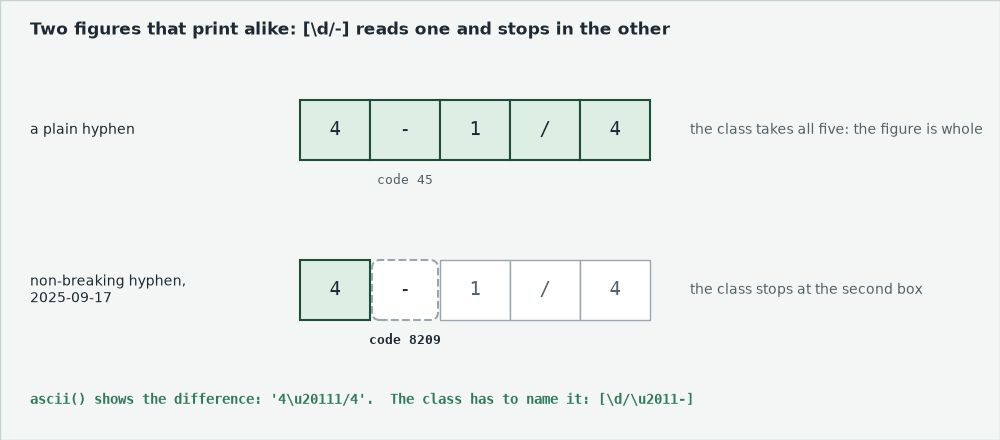

Printed, the range looks like any other; `ascii()` shows `\u2011`, the **non-breaking hyphen**, drawn like a hyphen so a line never breaks there.
To Python it is another character, as hidden as the EDA notebook's trailing space.

### How Common It Is

Q. How many statements hold it, and in which words?

In [24]:
# '\u2011' types the character in Python: statements holding it, then times in all
print(statements['text'].str.contains('\u2011').sum())
print(statements['text'].str.count('\u2011').sum())
# update() adds a list's items to a Counter's counts
pieces = Counter()
for text in statements['text']:
    pieces.update(re.findall(r'\S*\u2011\S*', text))
print(pieces.most_common(4))

26
38
[('mortgage‑backed', 22), ('longer‑term', 7), ('3‑3/4', 4), ('3‑1/2', 3)]


26 statements, 38 times, in words such as `mortgage-backed` as well as in figures.
`clean()` already turns it into a space, so both spellings give the same tokens.

### Widen the Class

Q. Let the class take the non-breaking hyphen too. Does every statement now give a range?

In [25]:
# the class: a digit, a slash, the non-breaking hyphen, or a plain hyphen, last
wide_pattern = r'[\d/\u2011-]+ to [\d/\u2011-]+ percent'
found_wide = statements['text'].str.findall(wide_pattern)
print(found_wide.str.len().value_counts().sort_index())
# .str[0] takes each list's first item: the range as the statement writes it
statements['range_text'] = found_wide.str[0]

text
1    44
2     2
Name: count, dtype: int64


All 46 now give a range.

### Which Rows Changed

Q. Five rows were empty. Did any row that had a match change its first range?

In [26]:
# Part 1's first match beside the new one; an empty row counts as changed
old_first = found.str[0]
changed = statements.loc[old_first != statements['range_text'], 'date']
print(len(changed), changed.tolist())
row = changed.index[0]
print(old_first[row], '|', ascii(statements.loc[row, 'range_text']))

6 ['2022-06-15', '2025-09-17', '2025-12-10', '2026-01-28', '2026-03-18', '2026-04-29']
1/2 to 1-3/4 percent | '1\u20111/2 to 1-3/4 percent'


6, not 5: on 2022-06-15 Part 1's pattern had read `1/2 to 1-3/4 percent`, the tail of `1-1/2`, cut at its hidden hyphen.
Part 1's tail trap again, under a count that looked right.

**Excel side by side.** Double-clicked, the CSV opens in the Windows code page and garbles the character; a copy written with `to_csv(..., encoding='utf-8-sig')` opens intact.

With that copy's statement of 2025-09-17 in C2:

<table align="left">
<tr><th align="left">Job</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">A character's code</td><td align="left"><code>=UNICODE(MID(C2, 715, 1))</code></td><td align="left">8209; a plain hyphen gives 45</td></tr>
<tr><td align="left">Swap it for a plain hyphen</td><td align="left"><code>=SUBSTITUTE(C2, UNICHAR(8209), "-")</code></td><td align="left"><code>4 to 4-1/4 percent</code></td></tr>
</table>
<br clear="left">

`UNICODE` and `UNICHAR` are in Excel 2013 and later.

**46 of 46, and one row was wrong while the count looked right.**

## 17.12 Every Statement Cleaned and Counted

### A Function on Every Row

Q. Clean all 46 statements and drop their stopwords.

In [27]:
def remove_stop_words(tokens):
    # the tokens not on nltk's list, as in 17.9
    return [token for token in tokens if token not in stop_words]


# Combining Part 2's .apply(): the function, without brackets, on every row
statements['tokens'] = statements['text'].apply(clean)
statements['kept'] = statements['tokens'].apply(remove_stop_words)

Q. How many tokens in all, and does 2023-11-01 still give 343 and 217?

In [28]:
# .str.len() on a column of lists counts each list's items
statements['n_tokens'] = statements['tokens'].str.len()
statements['n_kept'] = statements['kept'].str.len()
print(statements['n_tokens'].sum(), statements['n_kept'].sum())
statements.loc[statements['date'] == '2023-11-01', ['date', 'n_tokens', 'n_kept']]

16446 10204


,date,n_tokens,n_kept
22,2023-11-01,343,217


16,446 tokens, 10,204 kept, and 2023-11-01 ties with the hand counts of 17.8 and 17.9.

**Excel side by side.** `.apply()` is a formula filled down a column.

### A Word in Each Statement

Q. How many statements hold the word `balance`, and how often does `inflation` appear in each?

In [29]:
# .str.contains() takes a pattern: True where it is found; \b is Part 1's word edge
print(lower_text.str.contains(r'\bbalance\b').sum(), lower_text.str.contains('balance').sum())
# .str.count() counts the matches in each text
statements['inflation'] = lower_text.str.count(r'\binflation\b')
print(statements['inflation'].iloc[0], statements['inflation'].min(),
      statements['inflation'].max(), statements['inflation'].sum())

25 29
10 1 10 324


25 hold the word, 29 the letters, which `imbalances` also holds.

**Excel side by side.** With the texts in C2:C47, `=SUMPRODUCT(--ISNUMBER(SEARCH("balance", C2:C47)))` gives 29, the letters; `=(LEN(C2)-LEN(SUBSTITUTE(LOWER(C2), "inflation", "")))/LEN("inflation")` gives 10 for 2021-01-27.

### The Whole File's Top Tokens

Q. Which kept tokens are most common across all 46? Draw the top 15.

In [30]:
# one Counter, fed each statement's kept tokens in turn
all_counts = Counter()
for tokens in statements['kept']:
    all_counts.update(tokens)
print(len(all_counts), all_counts.most_common(3))

507 [('committee', 477), ('inflation', 324), ('policy', 196)]


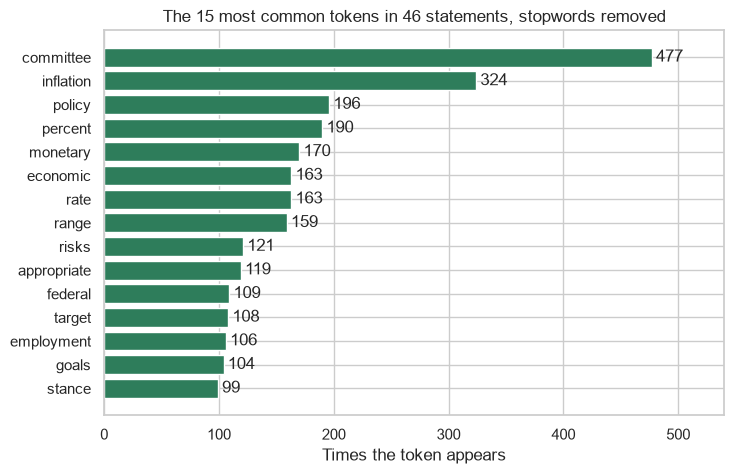

In [31]:
top15 = pd.Series(dict(all_counts.most_common(15)))[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top15.index, top15)
# padding= sets each label a little off the end of its bar
ax.bar_label(bars, padding=3)
# More Visualization's set_xlim(): room for the longest label
ax.set_xlim(0, 540)
ax.set_title('The 15 most common tokens in 46 statements, stopwords removed')
ax.set_xlabel('Times the token appears')
plt.show()

507 different tokens, and `inflation`'s 324 matches the column above.

**10,204 tokens, and the row for 2023-11-01 ties. Next, the counts as a table.**

## 17.13 A Document-Term Table

A **document-term table** has a row per document, a column per word, and a count in each cell: the way text reaches anything that works on numbers.

### Eight Words, 46 Rows

Q. Build the table for eight plain words.

In [32]:
terms = ['committee', 'inflation', 'percent', 'economic',
         'rate', 'risks', 'employment', 'labor']
# a Counter per statement, then one column per term
counters = statements['kept'].apply(Counter)
term_table = pd.DataFrame(index=statements['date'])
for term in terms:
    term_table[term] = [counter[term] for counter in counters]
print(term_table.iloc[0].tolist())
print(term_table.sum().tolist())

[10, 10, 7, 5, 2, 2, 6, 2]
[477, 324, 190, 163, 163, 121, 106, 62]


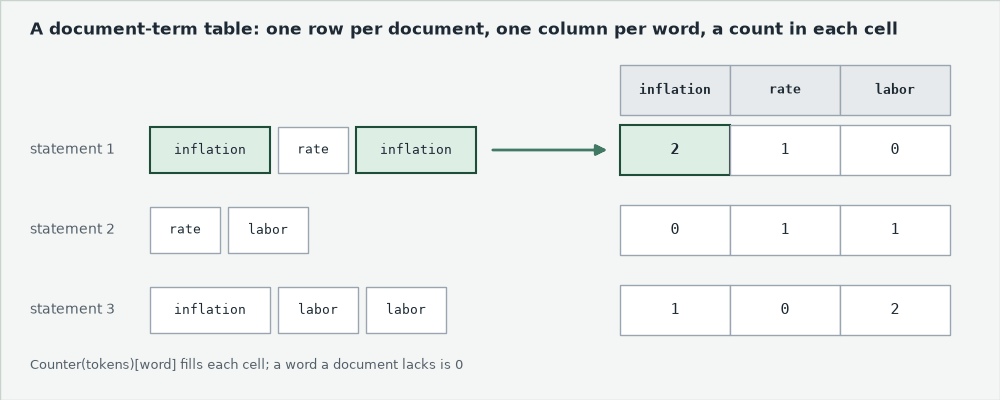

**Across the 46, the whole word rate appears 163 times: keep that number.**

### As a Heatmap

Q. Draw the table as a heatmap.

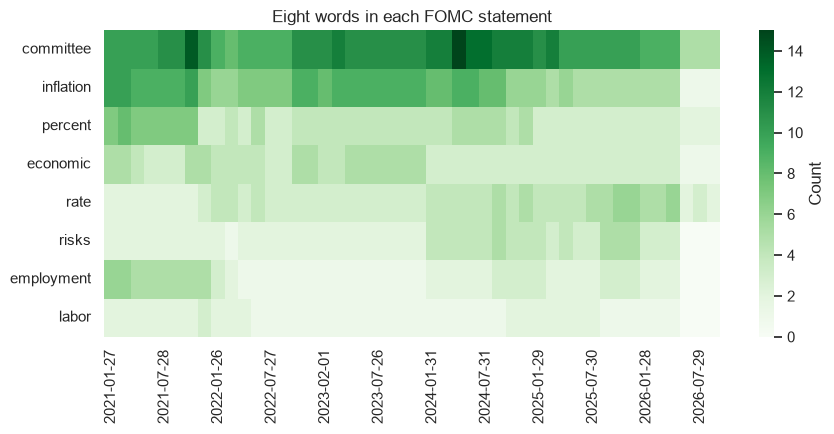

In [33]:
fig, ax = plt.subplots(figsize=(9, 4.5))
# .T turns the table on its side; xticklabels=4 labels every fourth date
# cbar_kws= names the colour bar
sns.heatmap(term_table.T, cmap='Greens', xticklabels=4, cbar_kws={'label': 'Count'}, ax=ax)
ax.set_title('Eight words in each FOMC statement')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

The last three columns are paler in every row: the three shortest statements, so a count leans on length.

**Excel side by side.** Conditional Formatting, Color Scales on the table of counts draws the same picture.

### Every Token

Q. Build the table for every different token. What share of the kept tokens do the 50 most common cover?

In [34]:
# a list of Counters as a table: a column per token, missing where a statement lacks it
# fillna(0) counts a missing token as 0, and astype(int) keeps the counts whole numbers
full_table = pd.DataFrame(list(counters)).fillna(0).astype(int)
top_50 = full_table.sum().nlargest(50).index
# .sum() twice: down each column, then across the totals
share = full_table[top_50].sum().sum() / full_table.sum().sum() * 100
print(full_table.shape, round(share, 1))
print((full_table.sum() == 1).sum())

(46, 507) 48.0
70


46 by 507; the top 50 cover 48.0 percent, and 70 tokens appear once.
scikit-learn's `CountVectorizer` builds this in one step, `max_features` keeping the most common.

**Excel side by side.** A pivot: statement in Rows, token in Columns, count in Values.

### Per 100 Tokens, by Year

Q. Per 100 kept tokens, how often does each word appear, by year?

In [35]:
# each row over its kept tokens; pandas Part 1's to_numpy() divides by position, not label
per_100 = term_table.div(statements['n_kept'].to_numpy(), axis=0) * 100
# groupby() also takes one value per row: each statement's year
per_100_by_year = per_100.groupby(statements['year'].to_numpy()).mean()
# axis=0 shades each column from its lowest year to its highest
per_100_by_year.style.format('{:.2f}').background_gradient(cmap='Greens', axis=0)

,committee,inflation,percent,economic,rate,risks,employment,labor
2021,3.47,2.93,2.13,1.32,0.68,0.64,1.69,0.68
2022,4.17,3.23,1.61,1.76,1.50,0.83,0.60,0.61
2023,5.18,4.13,1.86,2.21,1.40,0.93,0.47,0.47
2024,5.94,3.64,2.17,1.42,2.01,1.95,1.13,0.60
2025,5.05,2.57,1.46,1.46,2.30,1.94,1.22,0.80
2026,5.31,1.91,1.97,1.38,2.74,0.80,0.53,0.27


`inflation` runs 2.93 per 100 in 2021, 4.13 in 2023, 1.91 in 2026: a count over the total, as a market value weight is.

### Which Statements Hold a Word

Q. What share of each year's statements hold the whole word `balance`?

In [36]:
# True where a statement's kept tokens hold the word
# the mean of True and False is the share that is True
holds = pd.Series(['balance' in tokens for tokens in statements['kept']])
(holds.groupby(statements['year'].to_numpy()).mean() * 100).round(1)

2021      0.0
2022     75.0
2023      0.0
2024    100.0
2025    100.0
2026     50.0
dtype: float64

None in 2021 or 2023, all of 2024 and 2025: a share counts a statement once, however often it says the word.

**Excel side by side.** With the year in D2:D47 and TRUE or FALSE in E2:E47, `=COUNTIFS(D2:D47, 2026, E2:E47, TRUE)/COUNTIF(D2:D47, 2026)` gives 0.5.

**A count leans on length; per 100 tokens fixes it, and a share counts each statement once. Last: how much each statement changed.**

## 17.14 How Much Wording Changed

The **Jaccard similarity** of two statements is the different tokens in both over the different tokens in either: 1 for the same words, 0 for none shared.

### Predict 4: Two Short Lists

**Predict 4**

Q. `a = ['inflation', 'remains', 'elevated']` and `b = ['inflation', 'remains', 'somewhat', 'elevated', 'inflation']`. What is their similarity? Write down a number.

In [37]:
def similarity(first, second):
    # & keeps what is in both sets, | what is in either, as with NumPy Part 2's masks
    both = set(first) & set(second)
    either = set(first) | set(second)
    return len(both) / len(either)


a = ['inflation', 'remains', 'elevated']
b = ['inflation', 'remains', 'somewhat', 'elevated', 'inflation']
print(similarity(a, b))

0.75


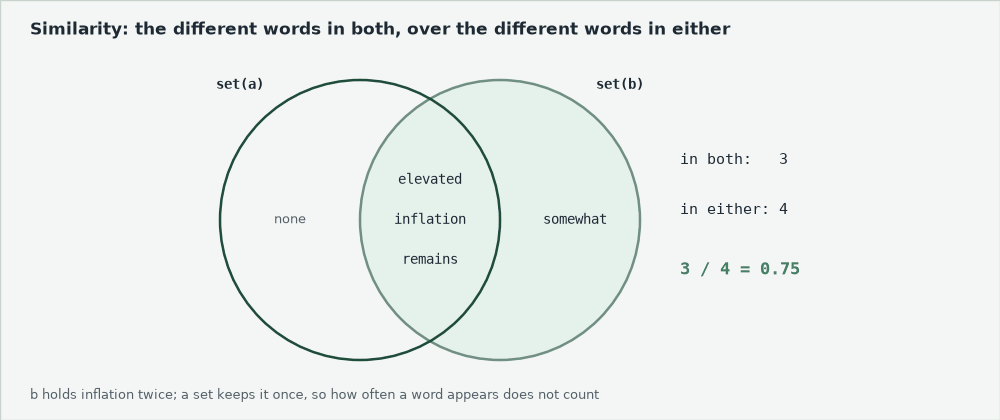

0.75: a set ignores repeats and order, so `inflation` twice counts once.

**Excel side by side.** `=UNIQUE(A2:A6)` lists each word once (Excel 2021 and Microsoft 365); with the sets in A2:A4 and B2:B5, `=SUMPRODUCT(COUNTIF(B2:B5, A2:A4))` gives 3 and `=COUNTA(A2:A4)+COUNTA(B2:B5)-3` gives 4.

### Each Statement Against the One Before

Q. How much of its wording does each statement share with the one before?

In [38]:
# the first has none before it: None, Python's value for nothing
values = [None]
for i in range(1, len(statements)):
    values.append(similarity(statements['kept'].iloc[i], statements['kept'].iloc[i - 1]))
statements['similarity'] = values
low = statements.loc[statements['similarity'].idxmin()]
high = statements.loc[statements['similarity'].idxmax()]
print(round(statements['similarity'].mean(), 3), low['date'], round(low['similarity'], 3),
      high['date'], round(high['similarity'], 3))
print(statements.loc[statements['similarity'] < 0.7, 'date'].tolist())

0.832 2026-06-17 0.196 2022-12-14 0.982
['2022-03-16', '2024-01-31', '2026-01-28', '2026-06-17', '2026-09-16']


Three of the five below 0.7 fall in 2026.

Q. Draw it, the low named.

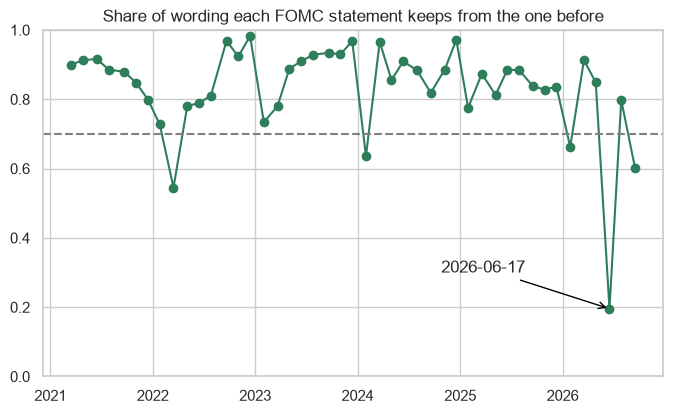

In [39]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(statements['meeting'], statements['similarity'], marker='o')
# pandas Part 1's axhline() at 0.7, and the lowest point named with 17.7's arrow
ax.axhline(0.7, color='grey', linestyle='--')
ax.annotate(low['date'], xy=(low['meeting'], low['similarity']),
            xytext=(low['meeting'] - pd.Timedelta(days=600), 0.3), arrowprops=arrow)
# More Visualization's set_ylim(): the whole range the measure can take
ax.set_ylim(0, 1)
ax.set_title('Share of wording each FOMC statement keeps from the one before')
plt.show()

The first statement has no point: nothing comes before it.
A low point says many words changed, not which, and not why.

### The Desk's Table

Q. Put the four columns together, one row per statement.

In [40]:
# .str.replace() is week 1's replace() on every row
# the hidden hyphen becomes a plain one, as Excel's SUBSTITUTE did
statements['rate_range'] = statements['range_text'].str.replace('\u2011', '-')
summary = statements[['date', 'words', 'rate_range', 'n_kept', 'inflation', 'similarity']]
print(summary.shape)
summary.tail(6).style.format({'similarity': '{:.3f}'}).hide(axis='index')

(46, 6)


date,words,rate_range,n_kept,inflation,similarity
2026-01-28,292,3-1/2 to 3-3/4 percent,178,5,0.663
2026-03-18,306,3-1/2 to 3-3/4 percent,186,5,0.913
2026-04-29,341,3-1/2 to 3-3/4 percent,202,5,0.849
2026-06-17,131,3-1/2 to 3-3/4 percent,80,1,0.196
2026-07-29,167,3-1/2 to 3-3/4 percent,101,1,0.798
2026-09-16,131,3-3/4 to 4 percent,79,1,0.602


**The note's four columns, every cell a count, a figure from the text, or a ratio of counts: no reading of policy.**

## You Can Now

By the end of this notebook, you can:

* Clean text in four steps and keep them in one function.
* Count tokens with `Counter` and remove nltk's stopwords.
* Stem tokens, knowing the stemmer's two limits.
* Find a hidden character with `ascii()` and widen a pattern to take it.
* Run text methods on a column with `.str` and `.apply()`.
* Build a document-term table, scale it by length, and compare statements by shared words.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...`, then run the check cell under it.
Run the next two cells first: one defines `check`, the other loads the statements, `clean()`, and `stop_words`.

In [41]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [42]:
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd

# a fresh copy of the statements; in Colab, from GitHub
if os.path.exists('../../../data/fomc_statements.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
statements = pd.read_csv(data_folder + 'fomc_statements.csv')
# the statement of 2022-09-21, for Exercise 1
other = statements.loc[statements['date'] == '2022-09-21', 'text'].iloc[0]


def clean(text):
    # the lesson's four steps
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    text = re.sub(r'\s+', ' ', text).strip()
    return text.split(' ')


nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

stop_words = stopwords.words('english')
print(statements.shape, len(stop_words))

(46, 3) 198


### Exercise 1

Q. Clean `other`. Store its tokens' count in **ex1_tokens**, the count after nltk's stopwords in **ex1_kept**, and the most common kept token in **ex1_top**.

In [43]:
ex1_tokens = ...
ex1_kept = ...
ex1_top = ...

In [44]:
check('Exercise 1 tokens', ex1_tokens, 315)
check('Exercise 1 kept', ex1_kept, 201)
check('Exercise 1 most common', ex1_top, 'committee')

Exercise 1 tokens: not attempted yet
Exercise 1 kept: not attempted yet
Exercise 1 most common: not attempted yet


### Exercise 2

Q. Add `words` and `year` columns. Store the year with the highest mean word count in **ex2_year**, that mean to 1 decimal place in **ex2_mean**, and the statements holding the whole word `uncertain` in **ex2_uncertain**. Draw the means as bars.

In [45]:
ex2_year = ...
ex2_mean = ...
ex2_uncertain = ...

In [46]:
check('Exercise 2 year', ex2_year, 2021)
check('Exercise 2 mean words', ex2_mean, 505.5)
check('Exercise 2 uncertain', ex2_uncertain, 19)

Exercise 2 year: not attempted yet
Exercise 2 mean words: not attempted yet
Exercise 2 uncertain: not attempted yet


### Exercise 3

Q. Build the document-term table of every kept token. Store its number of columns in **ex3_vocabulary** and the percent of kept tokens the top 20 cover, to 1 decimal place, in **ex3_share**.

In [47]:
ex3_vocabulary = ...
ex3_share = ...

In [48]:
check('Exercise 3 different tokens', ex3_vocabulary, 507)
check('Exercise 3 share covered', ex3_share, 30.0)

Exercise 3 different tokens: not attempted yet
Exercise 3 share covered: not attempted yet


### Exercise 4: AI check

Q. The lesson found a range in every statement. What will this AI-style answer print?

In [49]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# a number, the word to, a number, and percent
pattern = r'\d+ to \d+ percent'
found = statements['text'].str.findall(pattern)
ex4_statements = int((found.str.len() > 0).sum())
print(found[found.str.len() > 0].tolist())
print('Statements with a range:', ex4_statements)

[['4 to 1 percent'], ['4 to 4 percent'], ['4 to 5 percent'], ['4 to 5 percent'], ['4 to 4 percent'], ['4 to 4 percent']]
Statements with a range: 6


Q. Fix the cell above so **ex4_statements** is right, then store the first statement's range, as text, in **ex4_first**.

In [50]:
ex4_first = ...

In [51]:
check('Exercise 4 statements with a range', ex4_statements, 46)
check('Exercise 4 first range', ex4_first, '0 to 1/4 percent')

Exercise 4 statements with a range: not yet. You have 6
Exercise 4 first range: not attempted yet


### Exercise 5: AI check

Q. This AI-style answer counts the word rate. Part 1 found 3 in 2023-11-01, and 17.13 found 163 in all. What will it print? Fix it so **ex5_one** and **ex5_total** count the whole word.

In [52]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
one = statements.loc[statements['date'] == '2023-11-01', 'text'].iloc[0]
ex5_one = one.count('rate')
ex5_total = statements['text'].str.count('rate').sum()
print('In the statement of 2023-11-01:', ex5_one)
print('In all 46 statements:', ex5_total)

In the statement of 2023-11-01: 4
In all 46 statements: 188


In [53]:
check('Exercise 5 one statement', ex5_one, 3)
check('Exercise 5 all statements', ex5_total, 163)

Exercise 5 one statement: not yet. You have 4
Exercise 5 all statements: not yet. You have 188


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">How long each is</td><td align="left">131 to 614 words</td></tr>
<tr><td align="left">The range it states</td><td align="left">46 of 46</td></tr>
<tr><td align="left">A few plain words</td><td align="left">10,204 kept tokens; 2023-11-01 ties at 343 and 217</td></tr>
<tr><td align="left">Wording shared</td><td align="left">a mean of 0.832, a low of 0.196</td></tr>
</table>
<br clear="left">

Be proud of the hidden hyphen: five empty rows sent you looking, and the look found a sixth row that had been wrong all along.

Next, the case study asks whether a statement's wording can become one number, and how far to trust it.